# EVAL genmol both seeds

In [15]:
!pip install openpyxl rdkit msal

In [1]:
# import common libs
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
# import seaborn as sns


In [2]:
# Import the required classes
from capbet.evaluators.molgenevalsimple import MoleculeSetEvaluatorSimple
from capbet.core.wrappers.molecule import Molecule, MoleculeSet


# Load Data

In [3]:
# GT von Bayer
df = pd.read_excel("/home/ec2-user/SageMaker/data/raw/df_ICA_bionemo_eval_20250219.xlsx")
df.head()

,SUBSTANCE,SUBSTANCE_KEYS,std_smiles,AI_H,HSEC,AVEFA_PO_PROF,Lolium_PO_PROF,TRZAX_PO_PROF,AMAPA_PO_SEC_PROF,LOGD_neutral,LOGD_acid,SOL_mgL,SIP
0,BCS-DS23822,['BCS-DS23822'],C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)O)C2)CC(c2c...,318.0,317.0,NaN,NaN,NaN,NaN,0.89,1.93,3050.00,NaN
1,BCS-DH85862,['BCS-DH85862'],Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)N[C@H]3C=C[C@@H]...,338.0,231.0,NaN,NaN,NaN,NaN,2.72,2.80,28.30,NaN
2,BCS-CS64954,['BCS-CS64954'],COc1ccc(C2=NOC(C)(C(=O)NC3CC3)C2)cc1,0.0,0.0,NaN,NaN,NaN,NaN,1.79,1.77,68.65,NaN
3,BCS-CO63781,['BCS-CO63781'],CC1(C(=O)CCCC(=O)O)CC(c2cc(Cl)cc(Cl)c2)=NO1,120.0,92.0,NaN,NaN,NaN,NaN,1.11,2.72,1710.00,NaN
4,BCS-DC54916,['BCS-DC54916'],C=C[C@]1(C(=O)NCc2ccnc(OC)c2)CC(c2cc(F)cc(F)c2...,397.0,302.0,NaN,NaN,NaN,NaN,2.85,2.81,10.15,NaN


In [6]:
df_11 = pd.read_csv('../../data/interim/genmol/BCS-CE65417_R1_testmulti.csv')
df_12 = pd.read_csv('../../data/interim/genmol/BCS-CN20332_R1_testmulti.csv')
df_1 = pd.concat([df_11, df_12],ignore_index=True)
print(df_11.shape)
print(df_12.shape)
print(df_1.shape)
df_1.head(2)

(236, 2)
(337, 2)
(573, 2)


,smiles,score
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1,0.900
1,COC1=NOC(C(=O)NCc2cccc(I)c2)C1,0.835


In [13]:
df_21 = pd.read_csv("../../data/processed/genmol/BCS-CE65417_moo-w-qsar.csv")
df_22 = pd.read_csv("../../data/processed/genmol/BCS-CN20332_moo-w-qsar.csv")
df_2 = pd.concat([df_21, df_22],ignore_index=True)
print(df_21.shape)
print(df_22.shape)
print(df_2.shape)
df_2.drop(columns=['Unnamed: 0'], inplace=True)

df_2.head(2)

(446, 3)
(453, 3)
(899, 3)


,smiles,score
0,CCn1cc(CNC2=NOC(OC(=O)NCc3cccc(F)c3)C2)c(C)n1,0.789940
1,CCn1cc(CNC(=O)Cc2ccc(Br)cc2S)c(C)n1,0.784192


In [16]:

# Create sample datasets
print("\nCreating sample datasets...")

# Generated molecules (some valid, some invalid, some duplicates)
generated_smiles = df_1.smiles 

# Generated molecules (some valid, some invalid, some duplicates)
generated_smiles2 = df_2.smiles 

# Reference dataset (for novelty comparison)
reference_smiles = df.std_smiles

# Input dataset (for non-identicality comparison)
input_smiles = [
    "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
]

input_smiles2 = [
    "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
]
## first Bayer Seed
#m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#m1_name = "BCS-CN20332" 

## second seed
#m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
#m2_name = "BCS-CE65417"



Creating sample datasets...


In [17]:

# Create MoleculeSet objects
print("Creating MoleculeSet objects...")
print("°°° DF1")
generated_set = MoleculeSet()
generated_set.add_from_smiles_list(generated_smiles)
print("°°° DF2")
generated_set2 = MoleculeSet()
generated_set2.add_from_smiles_list(generated_smiles2)
print("°°° DF-ref = Bayer")
reference_set = MoleculeSet()
reference_set.add_from_smiles_list(reference_smiles)

input_set = MoleculeSet()
input_set.add_from_smiles_list(input_smiles, ["BCS-CN20332"])

input_set2 = MoleculeSet()
input_set2.add_from_smiles_list(input_smiles2, ["BCS-CE65417"])


Creating MoleculeSet objects...
°°° DF1
°°° DF2
°°° DF-ref = Bayer



Evaluating using fingerprint comparison...


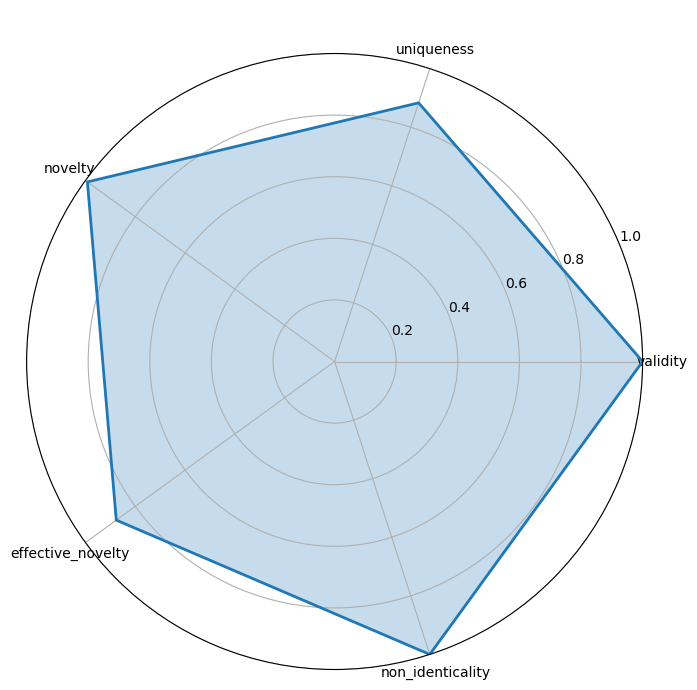

In [18]:

# Evaluate using fingerprint comparison
print("\nEvaluating using fingerprint comparison...")

fp_evaluator = MoleculeSetEvaluatorSimple(
    generated_set=generated_set,
    reference_set=reference_set,
    input_set=input_set,
    comparison_method='fingerprint',
    fingerprint_type='morgan',
    similarity_threshold=1
)

#fp_evaluator.print_report()
fp_evaluator.plot_metrics(title=" ", save_path="genmol_both_seeds_base.png")
fp_evaluator.add_run("GenMol (base)")


In [19]:
# Now update the evaluator with the second dataset (ref stays the same)
fp_evaluator.generated_set = generated_set2  # Replace with second dataset
fp_evaluator.input_set = input_set2
# Evaluate and add the first run
#fp_evaluator.print_report()
#fp_evaluator.plot_metrics(title="Molecule Metrics (Unguided LogP)", save_path="fingerprint_unguided_LogP.png")
fp_evaluator.add_run("GenMoL (guided)")



Comparing all runs...


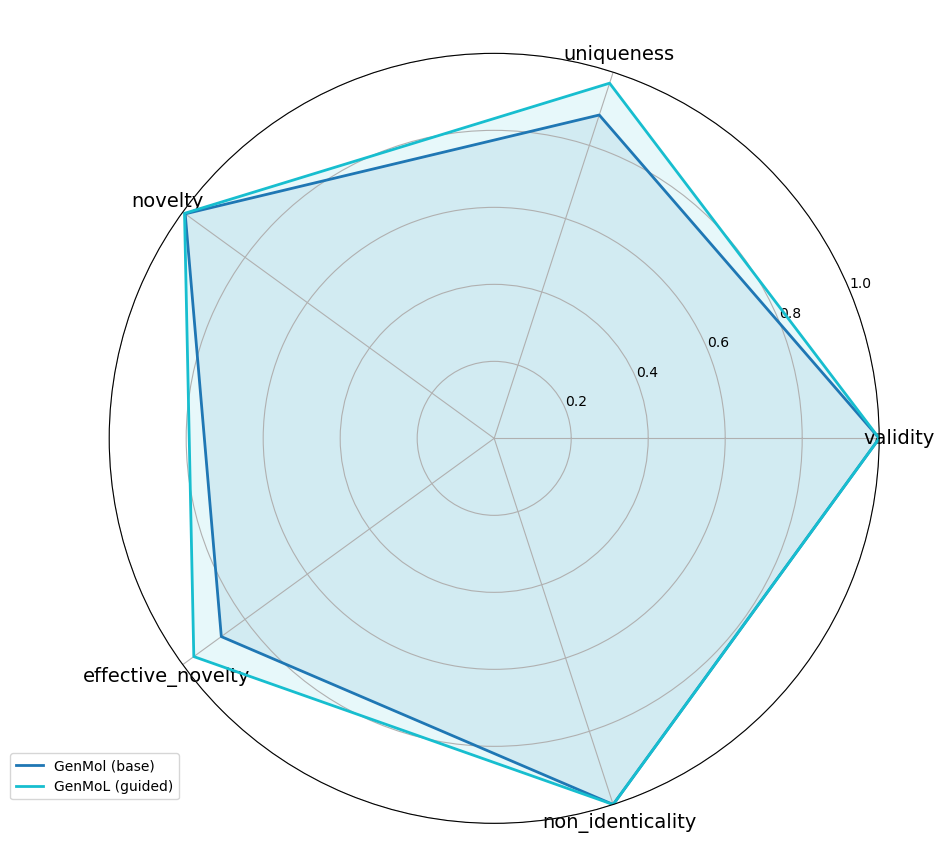

In [20]:

# Now compare all runs
print("\nComparing all runs...")
fp_evaluator.plot_multiple_runs(title=" ", save_path="Genmol_both_seeds.png")

In [21]:
fp_evaluator.print_report()

MOLECULE SET EVALUATION REPORT
Comparison Method: fingerprint
Fingerprint Type: morgan
Similarity Threshold: 1
------------------------------------------------------------
Validity: 1.0000 (100.00%)
Uniqueness: 0.9700 (97.00%)
Novelty: 0.9943 (99.43%)
Effective_novelty: 0.9644 (96.44%)
Non_identicality: 1.0000 (100.00%)
------------------------------------------------------------
Total molecules: 899
Valid molecules: 899
Unique molecules: 872
Novel molecules: 867
Non-identical molecules: 899

STATISTICS ACROSS RUNS
------------------------------------------------------------
Validity:
  mean: 1.0000
  median: 1.0000
  min: 1.0000
  max: 1.0000
  std: 0.0000

Uniqueness:
  mean: 0.9265
  median: 0.9265
  min: 0.8831
  max: 0.9700
  std: 0.0614

Novelty:
  mean: 0.9932
  median: 0.9932
  min: 0.9921
  max: 0.9943
  std: 0.0015

Effective_novelty:
  mean: 0.9202
  median: 0.9202
  min: 0.8761
  max: 0.9644
  std: 0.0624

Non_identicality:
  mean: 1.0000
  median: 1.0000
  min: 1.0000
  ma